# Tariff simulation and demand modelling

1. **Gas demand and weather** – Bayesian regression (PyMC) of monthly gas use on heating degree days and solar irradiance, for gas-heated homes in each SERL region.
2. **Predicting monthly electricity demand** – models using weather, calendar and region, trained on 2020–2022 and tested on 2023, against a seasonal-naive benchmark.
3. **Tariff comparison on real SERL consumption (2023)** – Octopus Agile vs a flat tariff, load shifting, household groups and regions.

**Inputs:** `data/Clean_Aggregated_data_2020_2023.csv`, the 2023 half-hourly file (via `serl_utils.py`) and published Octopus prices (via `tariff_utils.py`, cached in `outputs/artifacts/`).
**Outputs:** `outputs/gas_weather_bayes_summary.csv`, `outputs/ml_2023_test_results.csv`, `outputs/tariff_*.csv`.

Earlier versions of this notebook pooled every household group and unit into one machine-learning table, with features such as a "24-hour lag" and time-of-day terms that are meaningless for monthly data, and ran the tariff, clustering and forecasting classes on synthetic data. Those parts are replaced by sections 1–3.


## 1. Gas demand and weather (Bayesian regression)

**Data:** monthly mean gas use (kWh/day) of gas-heated homes without PV, in each of the 11 regions, 2020–2023 (528 region-months), with SERL's region-matched heating degree days (HDD) and solar irradiance.

**Model:** gas = region intercept + β_HDD · HDD + β_solar · solar + noise. Region intercepts share a common prior (partial pooling). Predictors are standardised for sampling; the effect of HDD is reported back in kWh/day per degree-day. Temperature is left out because it is almost a mirror image of HDD (correlation −0.99), which would make both coefficients uninterpretable.


Initializing NUTS using jitter+adapt_diag...


528 region-months; gas 5.2–85.6 kWh/day


Sequential sampling (4 chains in 1 job)


NUTS: [mu_alpha, sigma_alpha, alpha, beta_hdd, beta_solar, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 6 seconds.


Sampling: [gas]


               mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  r_hat
mu_alpha     33.357  1.172  30.996   35.489      0.020    0.025    3776.0    2651.0    1.0
sigma_alpha   3.682  1.008   2.115    5.565      0.017    0.026    4451.0    2771.0    1.0
beta_hdd     18.937  0.290  18.398   19.481      0.005    0.004    3631.0    3215.0    1.0
beta_solar   -4.639  0.287  -5.195   -4.107      0.005    0.004    3711.0    3267.0    1.0
sigma         4.744  0.148   4.471    5.030      0.002    0.003    6268.0    2518.0    1.0

Convergence: max r_hat = 1.000, min bulk ESS = 3631 (4 chains x 1000 draws)
Each extra heating degree-day per day adds 5.21 kWh/day of gas (94% HDI 5.06 to 5.36).
Bayesian R² = 0.920 (sd 0.005)


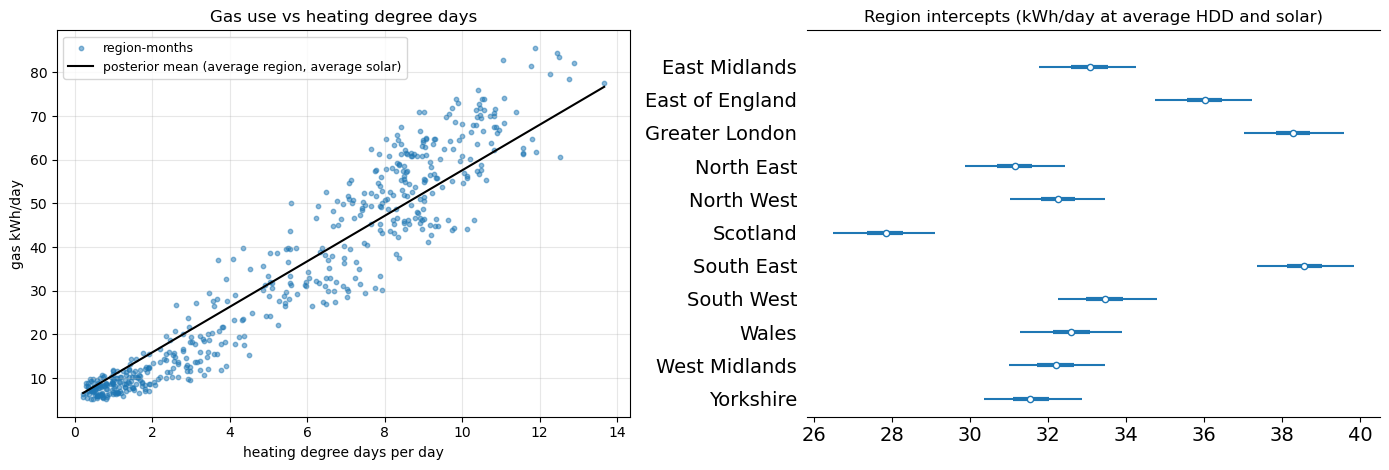

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az
import serl_utils as su

warnings.filterwarnings("ignore", category=FutureWarning)
monthly = su.load_monthly(su.CLEAN_CSV)
SLICE = dict(quantity="Gas", unit="kWh/day", fuel="Gas", pv="No")
panels = {v: su.monthly_panel(monthly, segment="region", value=v, **SLICE)
          for v in ("mean", "mean_hdd", "mean_solar")}
long = pd.concat({k: p.stack() for k, p in panels.items()}, axis=1).reset_index()
long.columns = ["date", "region", "gas", "hdd", "solar"]
regions = sorted(long["region"].unique())
region_idx = long["region"].map({r: i for i, r in enumerate(regions)}).to_numpy()
hdd_mu, hdd_sd = long["hdd"].mean(), long["hdd"].std()
sol_mu, sol_sd = long["solar"].mean(), long["solar"].std()
hdd_z = ((long["hdd"] - hdd_mu) / hdd_sd).to_numpy()
sol_z = ((long["solar"] - sol_mu) / sol_sd).to_numpy()
print(f"{len(long)} region-months; gas {long['gas'].min():.1f}–{long['gas'].max():.1f} kWh/day")

with pm.Model(coords={"region": regions}) as gas_model:
    mu_alpha = pm.Normal("mu_alpha", mu=long["gas"].mean(), sigma=20)
    sigma_alpha = pm.HalfNormal("sigma_alpha", sigma=10)
    alpha = pm.Normal("alpha", mu=mu_alpha, sigma=sigma_alpha, dims="region")
    beta_hdd = pm.Normal("beta_hdd", mu=0, sigma=20)
    beta_solar = pm.Normal("beta_solar", mu=0, sigma=20)
    sigma = pm.HalfNormal("sigma", sigma=10)
    mu = alpha[region_idx] + beta_hdd * hdd_z + beta_solar * sol_z
    pm.Normal("gas", mu=mu, sigma=sigma, observed=long["gas"].to_numpy())
    trace = pm.sample(1000, tune=1000, chains=4, cores=1, target_accept=0.9, random_seed=42, progressbar=False)
    ppc = pm.sample_posterior_predictive(trace, random_seed=42, progressbar=False)

summary = az.summary(trace, var_names=["mu_alpha", "sigma_alpha", "beta_hdd", "beta_solar", "sigma"], hdi_prob=0.94)
print(summary.round(3).to_string())
full = az.summary(trace, hdi_prob=0.94)
print(f"\nConvergence: max r_hat = {full['r_hat'].max():.3f}, min bulk ESS = {full['ess_bulk'].min():.0f} (4 chains x 1000 draws)")

per_dd = trace.posterior["beta_hdd"] / hdd_sd
lo, hi = az.hdi(per_dd, hdi_prob=0.94)["beta_hdd"].to_numpy()
print(f"Each extra heating degree-day per day adds {float(per_dd.mean()):.2f} kWh/day of gas (94% HDI {lo:.2f} to {hi:.2f}).")
pred = ppc.posterior_predictive["gas"].stack(sample=("chain", "draw")).to_numpy().T
r2 = az.r2_score(long["gas"].to_numpy(), pred)
print(f"Bayesian R² = {r2['r2']:.3f} (sd {r2['r2_std']:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].scatter(long["hdd"], long["gas"], s=10, alpha=0.5, label="region-months")
grid = np.linspace(long["hdd"].min(), long["hdd"].max(), 50)
post = trace.posterior
line = (post["mu_alpha"].mean().item() + post["beta_hdd"].mean().item() * (grid - hdd_mu) / hdd_sd)
axes[0].plot(grid, line, color="black", label="posterior mean (average region, average solar)")
axes[0].set_xlabel("heating degree days per day"); axes[0].set_ylabel("gas kWh/day")
axes[0].set_title("Gas use vs heating degree days"); axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)
az.plot_forest(trace, var_names=["alpha"], combined=True, hdi_prob=0.94, ax=axes[1])
axes[1].set_yticklabels(list(reversed(regions)))
axes[1].set_title("Region intercepts (kWh/day at average HDD and solar)")
plt.tight_layout(); plt.show()

summary.to_csv("outputs/gas_weather_bayes_summary.csv")

## 2. Predicting monthly electricity demand

**Data:** monthly mean electricity imports (kWh/day), all households in each region, 2020–2023. **Features:** heating degree days, solar irradiance, month of year (as sine/cosine), a time index (trend) and region. **Split by time:** train on 2020–2022, test on all of 2023, so the test is a genuine forecast of an unseen year. A random split would let the models see 2023 neighbours of each test month.

Models: seasonal naive (same month of 2022), linear regression, random forest and gradient boosting.


train: 396 region-months (2020–2022), test: 132 (2023)



2023 test set (kWh/day; positive bias = over-forecast)
                                    MAE   RMSE  MAPE %  mean bias
Gradient boosting                 0.398  0.501   4.659      0.312
Seasonal naive (same month 2022)  0.414  0.541   4.710      0.257
Random forest                     0.541  0.661   6.555      0.374
Linear regression                 0.678  0.825   8.495     -0.456



Permutation importance on the 2023 test set (Gradient boosting; increase in MAE when a feature is shuffled)
hdd          0.889
region       0.225
solar        0.120
month_cos    0.024
t            0.000
month_sin   -0.000


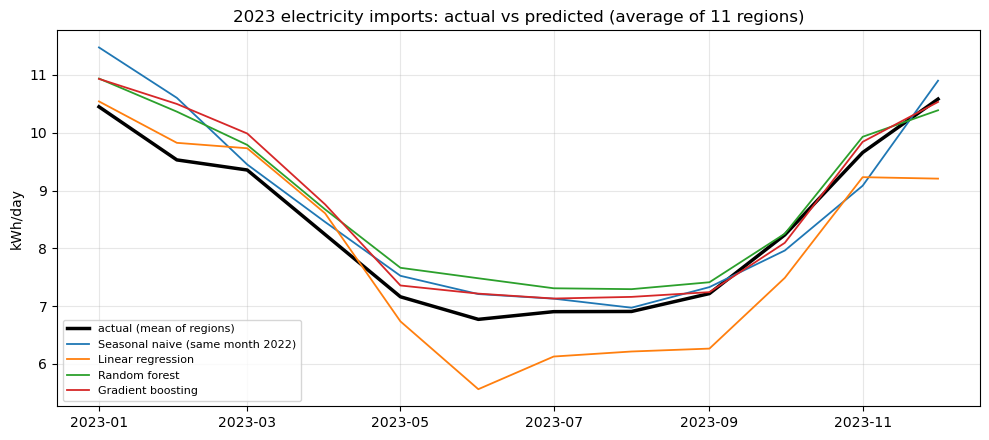

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance

E = dict(quantity="Electricity imports", unit="kWh/day")
cols = {v: su.monthly_panel(monthly, segment="region", value=v, **E) for v in ("mean", "mean_hdd", "mean_solar")}
data = pd.concat({k: p.stack() for k, p in cols.items()}, axis=1).reset_index()
data.columns = ["date", "region", "y", "hdd", "solar"]
data["month_sin"] = np.sin(2 * np.pi * data["date"].dt.month / 12)
data["month_cos"] = np.cos(2 * np.pi * data["date"].dt.month / 12)
data["t"] = (data["date"].dt.year - 2020) * 12 + data["date"].dt.month - 1
X = pd.concat([data[["hdd", "solar", "month_sin", "month_cos", "t"]],
               pd.get_dummies(data["region"], prefix="region", drop_first=True, dtype=float)], axis=1)
train, test = data["date"] < "2023-01-01", data["date"] >= "2023-01-01"
print(f"train: {train.sum()} region-months (2020–2022), test: {test.sum()} (2023)")

last_year = data.set_index(["region", "date"])["y"]
naive = [last_year[(r, d - pd.DateOffset(years=1))] for r, d in zip(data.loc[test, "region"], data.loc[test, "date"])]
preds = {"Seasonal naive (same month 2022)": np.array(naive)}
fitted = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=42),
    "Gradient boosting": GradientBoostingRegressor(random_state=42),
}
for name, model in fitted.items():
    model.fit(X[train], data.loc[train, "y"])
    preds[name] = model.predict(X[test])

y_test = data.loc[test, "y"].to_numpy()
results = pd.DataFrame({name: {"MAE": np.mean(np.abs(y_test - p)), "RMSE": np.sqrt(np.mean((y_test - p) ** 2)),
                               "MAPE %": 100 * np.mean(np.abs(y_test - p) / y_test),
                               "mean bias": np.mean(p - y_test)} for name, p in preds.items()}).T
print("\n2023 test set (kWh/day; positive bias = over-forecast)")
print(results.sort_values("MAE").round(3).to_string())

best_tree = min(["Random forest", "Gradient boosting"], key=lambda n: results.loc[n, "MAE"])
imp = permutation_importance(fitted[best_tree], X[test], y_test, n_repeats=20, random_state=42)
importance = (pd.Series(imp.importances_mean, index=X.columns)
              .groupby(lambda c: "region" if c.startswith("region_") else c).sum().sort_values(ascending=False))
print(f"\nPermutation importance on the 2023 test set ({best_tree}; increase in MAE when a feature is shuffled)")
print(importance.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
monthly_mean = data[test].assign(**{n: p for n, p in preds.items()}).groupby("date")[["y", *preds]].mean()
ax.plot(monthly_mean.index, monthly_mean["y"], color="black", linewidth=2.5, label="actual (mean of regions)")
for n in preds:
    ax.plot(monthly_mean.index, monthly_mean[n], label=n, linewidth=1.3)
ax.set_ylabel("kWh/day"); ax.set_title("2023 electricity imports: actual vs predicted (average of 11 regions)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
results.to_csv("outputs/ml_2023_test_results.csv")

**Reading the results**
- Gradient boosting is the most accurate model for 2023, but only slightly better than repeating each region's 2022 value for the same month (MAE 0.40 vs 0.41 kWh/day). Once last year's seasonal pattern is known, weather and calendar features add little.
- The `mean bias` column shows the trend problem. Tree models cannot extrapolate beyond the training years, so they over-forecast 2023 (+0.3 to +0.4 kWh/day). Linear regression carries the steep 2022 fall too far and under-forecasts (−0.46 kWh/day).
- Heating degree days are by far the most important feature. The time index adds nothing to the tree model, for the reason above.


## Tariff comparison on real SERL consumption (2023)

How much would the average SERL household have paid in 2023 on a **dynamic tariff** (Octopus Agile, a new price every half-hour) compared with a **flat tariff** (Flexible Octopus, which follows the Ofgem price cap), and how much more could it save by moving some evening-peak use to cheaper times?

**Consumption (SERL, `serl_utils`).** The annual mean half-hourly profile for 2023 gives the shape of a day, separately for weekdays and weekends. The monthly mean daily consumption gives each month's level, so winter months use more than summer months. Quantity is *Electricity imports* (what is bought from the grid), whole sample unless stated.

**Prices (Octopus Energy public API, `tariff_utils`).** Published 2023 rates for GSP region C (London): Agile half-hourly unit rates, Flexible quarterly unit rates (direct debit), and both standing charges, all including VAT. Downloads are cached in `outputs/artifacts/`, so later runs work offline.

**Things to keep in mind**
- The Energy Price Guarantee discount households received in January–June 2023 is not applied consistently in the published flat rates (Apr–Jun shows the undiscounted 52.1p). **July–December 2023 is the cleanest comparison**; quarters are shown separately so the effect is visible.
- SERL does not state whether its half-hour labels are UTC or UK clock time. UTC is assumed, and the result is shown under both readings below.
- The daily *shape* is an annual average, so it does not change with the seasons (only the level does).
- Export income for PV homes is not included.


In [3]:
# Prices: 2023 Agile and Flexible Octopus rates for one region (cached after the first download)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import serl_utils as su
import tariff_utils as tu

REGION = "C"                               # GSP region letter (C = London)
START, END = "2023-01-01", "2024-01-01"
H2_START = "2023-07-01"                    # no Energy Price Guarantee distortion from here
QUANTITY = "Electricity imports"

agile = tu.half_hourly_rates(tu.fetch_unit_rates(tu.AGILE_PRODUCT, tu.agile_code(REGION), START, END), START, END)
flat = tu.half_hourly_rates(tu.fetch_unit_rates(tu.FLEX_PRODUCT, tu.flex_code(REGION), START, END), START, END)
standing_agile = tu.daily_standing_charges(tu.fetch_standing_charges(tu.AGILE_PRODUCT, tu.agile_code(REGION), START, END), START, END)
standing_flat = tu.daily_standing_charges(tu.fetch_standing_charges(tu.FLEX_PRODUCT, tu.flex_code(REGION), START, END), START, END)
TARIFFS = {"Agile": (agile, standing_agile), "Flexible (flat)": (flat, standing_flat)}

local = agile.index.tz_convert(tu.UK_TZ)
quarter = local.quarter
print("Mean unit rate by quarter (p/kWh, inc. VAT)")
print(pd.DataFrame({"Agile": agile.groupby(quarter).mean(), "Flexible (flat)": flat.groupby(quarter).mean()},
                   index=pd.Index([1, 2, 3, 4], name="quarter")).round(2))
print(f"Agile range: {agile.min():.2f} to {agile.max():.2f} p/kWh; {(agile < 0).sum()} half-hours below zero")
print(f"Standing charges (p/day): Agile {sorted(standing_agile.unique())}, Flexible {sorted(np.round(standing_flat.unique(), 2))}")

Mean unit rate by quarter (p/kWh, inc. VAT)
         Agile  Flexible (flat)
quarter                        
1        27.09            35.80
2        20.25            52.08
3        18.17            31.19
4        18.94            28.43
Agile range: -18.12 to 65.06 p/kWh; 215 half-hours below zero
Standing charges (p/day): Agile [31.5105], Flexible [31.51, 36.54]


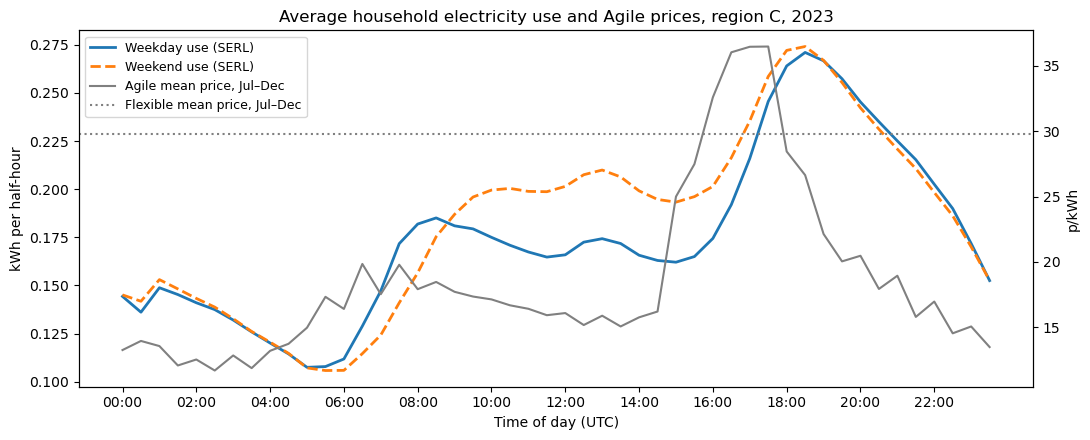

Daily use: weekday 8.39, weekend 8.77 kWh/day; peak half-hour 18:30


In [4]:
# SERL 2023 profiles (shape) and monthly levels, and how Agile prices line up with the evening peak
hh = su.load_half_hourly([2023])
monthly = su.load_monthly()
profiles = {d: su.daily_profile(hh, 2023, QUANTITY, "Wh", to_kwh=True, weekday_weekend=d)
            for d in ("both", "weekday", "weekend")}
level = su.monthly_series(monthly, QUANTITY, "kWh/day")

h2 = agile.index >= pd.Timestamp(H2_START, tz="UTC")
agile_by_slot = agile[h2].groupby(agile[h2].index.strftime("%H:%M")).mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(range(48), profiles["weekday"].to_numpy(), label="Weekday use (SERL)", linewidth=2)
ax.plot(range(48), profiles["weekend"].to_numpy(), label="Weekend use (SERL)", linewidth=2, linestyle="--")
ax.set_ylabel("kWh per half-hour")
ax.set_xticks(range(0, 48, 4), [f"{h:02d}:00" for h in range(0, 24, 2)])
ax.set_xlabel("Time of day (UTC)")
ax2 = ax.twinx()
ax2.plot(range(48), agile_by_slot.to_numpy(), color="grey", linewidth=1.5, label="Agile mean price, Jul–Dec")
ax2.axhline(flat[h2].mean(), color="grey", linestyle=":", label="Flexible mean price, Jul–Dec")
ax2.set_ylabel("p/kWh")
lines = ax.get_legend_handles_labels(); lines2 = ax2.get_legend_handles_labels()
ax.legend(lines[0] + lines2[0], lines[1] + lines2[1], loc="upper left", fontsize=9)
ax.set_title(f"Average household electricity use and Agile prices, region {REGION}, 2023")
plt.tight_layout(); plt.show()

print(f"Daily use: weekday {profiles['weekday'].sum():.2f}, weekend {profiles['weekend'].sum():.2f} kWh/day; "
      f"peak half-hour {profiles['both'].idxmax()}")

In [5]:
# Bills for the average SERL household, by quarter, under both readings of SERL's time labels
idx = tu.half_hour_index(START, END)
tables = {}
for label, utc in (("UTC (assumed)", True), ("UK clock time", False)):
    kwh = tu.build_consumption(profiles, level, idx, profile_time_is_utc=utc)
    t = tu.compare(kwh, TARIFFS, by="Q")
    tables[label] = t.pivot(index="period", columns="tariff", values="total_gbp")

kwh = tu.build_consumption(profiles, level, idx, profile_time_is_utc=True)
quarterly = tu.compare(kwh, TARIFFS, by="Q")
summary = quarterly.pivot(index="period", columns="tariff", values=["kwh", "total_gbp", "unit_p_per_kwh"])
summary.columns = [f"{a} | {b}" for a, b in summary.columns]
summary = summary.drop(columns="kwh | Flexible (flat)").rename(columns={"kwh | Agile": "kWh"})
print("Average SERL household, region C prices (totals include standing charges)")
print(summary.round(2).to_string())

h2_kwh = kwh[kwh.index >= pd.Timestamp(H2_START, tz="UTC")]
b_agile = tu.bill(h2_kwh, agile, standing_agile)
b_flat = tu.bill(h2_kwh, flat, standing_flat)
print(f"\nJul–Dec 2023 ({b_agile['kwh']:.0f} kWh): Agile £{b_agile['total_gbp']:.2f} vs flat £{b_flat['total_gbp']:.2f} "
      f"→ Agile {100 * (1 - b_agile['total_gbp'] / b_flat['total_gbp']):.1f}% cheaper "
      f"(effective {b_agile['unit_p_per_kwh']:.2f} vs {b_flat['unit_p_per_kwh']:.2f} p/kWh)")
diff = (tables["UK clock time"] - tables["UTC (assumed)"]).abs().max().max()
print(f"Sensitivity: reading SERL times as UK clock time changes any quarterly bill by at most £{diff:.2f}")

Average SERL household, region C prices (totals include standing charges)
           kWh  total_gbp | Agile  total_gbp | Flexible (flat)  unit_p_per_kwh | Agile  unit_p_per_kwh | Flexible (flat)
period                                                                                                                  
2023Q1  891.60             277.95                       347.53                   27.99                             35.80
2023Q2  679.58             170.75                       387.19                   20.91                             52.08
2023Q3  648.83             151.35                       236.00                   18.86                             31.19
2023Q4  881.38             203.92                       284.18                   19.85                             28.43

Jul–Dec 2023 (1530 kWh): Agile £355.23 vs flat £520.09 → Agile 31.7% cheaper (effective 19.43 vs 29.60 p/kWh)
Sensitivity: reading SERL times as UK clock time changes any quarterly bill by at most £2

In [6]:
# Load shifting on Agile: move part of the 16:00–19:00 (UK time) use into each day's 8 cheapest half-hours
peak_local = h2_kwh.index.tz_convert(tu.UK_TZ).strftime("%H:%M")
in_peak = (peak_local >= "16:00") & (peak_local < "19:00")
rows = []
for frac in (0.0, 0.1, 0.2, 0.3):
    shifted = tu.shift_peak(h2_kwh, agile, frac)
    b = tu.bill(shifted, agile, standing_agile)
    rows.append({"shifted from peak": f"{frac:.0%}",
                 "Agile bill £": b["total_gbp"],
                 "saving vs no shift £": b_agile["total_gbp"] - b["total_gbp"],
                 "saving vs flat £": b_flat["total_gbp"] - b["total_gbp"],
                 "effective p/kWh": b["unit_p_per_kwh"],
                 "peak-window kWh": shifted[in_peak].sum()})
shift_table = pd.DataFrame(rows)
print(f"Average SERL household, Jul–Dec 2023, region {REGION} (flat bill £{b_flat['total_gbp']:.2f})")
print(shift_table.round(2).to_string(index=False))

Average SERL household, Jul–Dec 2023, region C (flat bill £520.09)
shifted from peak  Agile bill £  saving vs no shift £  saving vs flat £  effective p/kWh  peak-window kWh
               0%        355.23                  0.00            164.86            19.43           230.26
              10%        349.75                  5.48            170.34            19.07           207.23
              20%        344.27                 10.96            175.82            18.71           184.21
              30%        338.79                 16.44            181.30            18.35           161.18


                          group  kWh/day  peak share %  flat £  Agile £  Agile saving %  Agile p/kWh  extra saving from 20% shift £
                 All households     8.31         15.04  519.89   355.45           31.63        19.45                          10.95
                             PV     8.77         12.92  541.22   358.72           33.72        18.65                          10.08
                          No PV     8.28         15.20  518.67   355.36           31.49        19.51                          11.02
                    Gas heating     7.84         15.43  494.92   340.71           31.16        19.59                          10.58
               Electric heating    11.78         12.60  702.41   459.13           34.63        18.50                          13.17
 IMD quintile 1 (most deprived)     6.95         15.45  446.26   307.89           31.01        19.54                           9.38
                 IMD quintile 2     7.66         15.10  484.74   332.40     

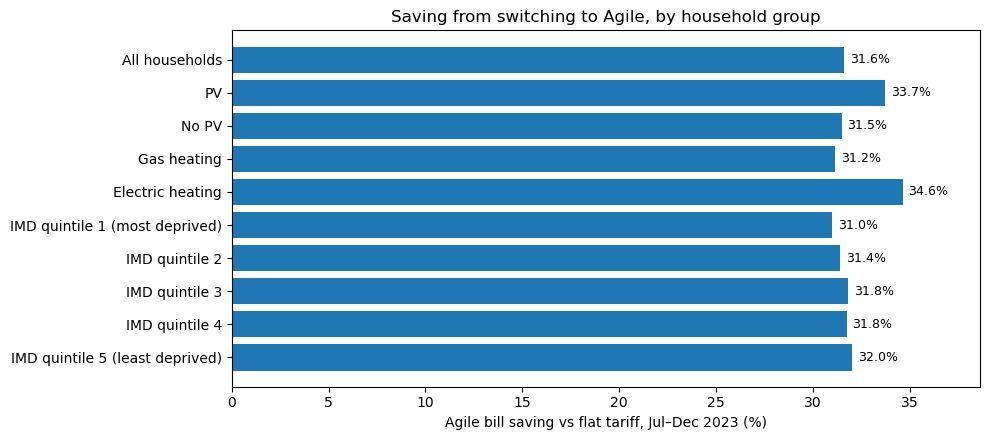

In [7]:
# Who benefits? The same comparison for household groups (Jul–Dec 2023, same region C prices for everyone)
# SERL gives weekday/weekend profiles only for the whole sample, so every group here uses its "both" profile.
groups = [("All households", {}),
          ("PV", {"pv": "Yes"}), ("No PV", {"pv": "No"}),
          ("Gas heating", {"fuel": "Gas"}), ("Electric heating", {"fuel": "Electric"})]
groups += [(f"IMD quintile {q}" + (" (most deprived)" if q == "1" else " (least deprived)" if q == "5" else ""),
            {"segment": "IMD_quintile", "segment_value": q}) for q in "12345"]

h2_idx = tu.half_hour_index(H2_START, END)
rows = []
for name, filt in groups:
    prof = su.daily_profile(hh, 2023, QUANTITY, "Wh", to_kwh=True, **filt)
    lvl = su.monthly_series(monthly, QUANTITY, "kWh/day", **filt)
    g_kwh = tu.build_consumption({"both": prof}, lvl, h2_idx)
    ba, bf = tu.bill(g_kwh, agile, standing_agile), tu.bill(g_kwh, flat, standing_flat)
    bs = tu.bill(tu.shift_peak(g_kwh, agile, 0.2), agile, standing_agile)
    t = g_kwh.index.tz_convert(tu.UK_TZ).strftime("%H:%M")
    rows.append({"group": name, "kWh/day": g_kwh.sum() / 184,
                 "peak share %": 100 * g_kwh[(t >= "16:00") & (t < "19:00")].sum() / g_kwh.sum(),
                 "flat £": bf["total_gbp"], "Agile £": ba["total_gbp"],
                 "Agile saving %": 100 * (1 - ba["total_gbp"] / bf["total_gbp"]),
                 "Agile p/kWh": ba["unit_p_per_kwh"],
                 "extra saving from 20% shift £": ba["total_gbp"] - bs["total_gbp"]})
group_table = pd.DataFrame(rows)
print(group_table.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(group_table["group"], group_table["Agile saving %"])
ax.invert_yaxis()
for y, v in enumerate(group_table["Agile saving %"]):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, group_table["Agile saving %"].max() + 4)
ax.set_xlabel("Agile bill saving vs flat tariff, Jul–Dec 2023 (%)")
ax.set_title("Saving from switching to Agile, by household group")
plt.tight_layout(); plt.show()

### By region: each region's own consumption and its own prices

Each SERL region's 2023 profile and monthly levels are priced with the Agile and Flexible rates of the matching electricity distribution (GSP) region. The mapping is approximate where boundaries differ: Wales → South Wales (K), Scotland → South Scotland (N), South East → South Eastern (J).


Jul–Dec 2023, each region with its own prices
         region GSP  kWh/day  flat p/kWh  Agile p/kWh  flat £  Agile £  Agile saving %  extra saving from 20% shift £
 Greater London   C     8.26       29.58        19.19  516.78   349.61           32.35                          10.03
East of England   A     8.59       29.10        20.43  537.14   391.49           27.12                          11.98
     North West   G     8.10       28.37        20.50  514.52   382.18           25.72                          11.33
  East Midlands   B     8.34       27.91        19.85  517.64   385.65           25.50                          12.21
     South East   J     8.91       29.29        21.06  564.18   420.84           25.41                          11.85
      Yorkshire   M     8.18       27.69        19.76  515.92   385.51           25.28                          11.74
       Scotland   N     8.02       28.07        20.50  524.86   392.89           25.14                          11.40
  West Mid

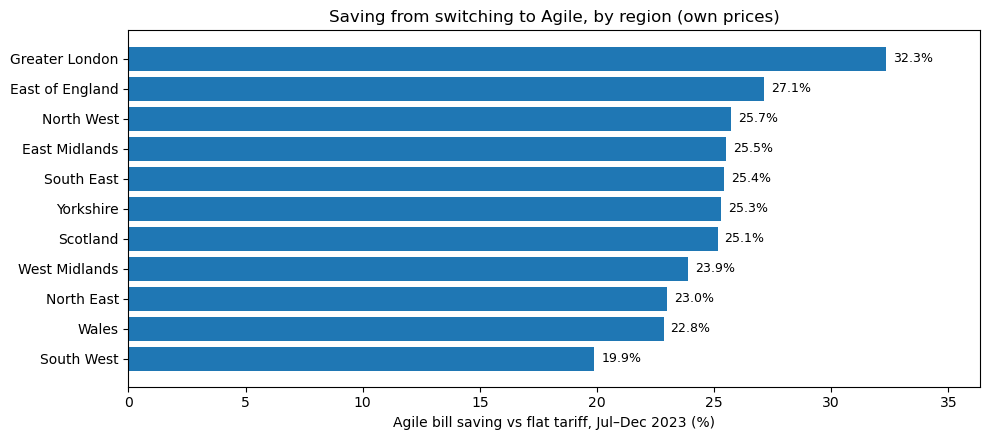

In [8]:
GSP_REGION = {"East of England": "A", "East Midlands": "B", "Greater London": "C", "West Midlands": "E",
              "North East": "F", "North West": "G", "South East": "J", "Wales": "K", "South West": "L",
              "Yorkshire": "M", "Scotland": "N"}
rows = []
for region, letter in GSP_REGION.items():
    ag = tu.half_hourly_rates(tu.fetch_unit_rates(tu.AGILE_PRODUCT, tu.agile_code(letter), START, END), START, END)
    fl = tu.half_hourly_rates(tu.fetch_unit_rates(tu.FLEX_PRODUCT, tu.flex_code(letter), START, END), START, END)
    s_ag = tu.daily_standing_charges(tu.fetch_standing_charges(tu.AGILE_PRODUCT, tu.agile_code(letter), START, END), START, END)
    s_fl = tu.daily_standing_charges(tu.fetch_standing_charges(tu.FLEX_PRODUCT, tu.flex_code(letter), START, END), START, END)
    filt = {"segment": "region", "segment_value": region}
    prof = su.daily_profile(hh, 2023, QUANTITY, "Wh", to_kwh=True, **filt)
    r_kwh = tu.build_consumption({"both": prof}, su.monthly_series(monthly, QUANTITY, "kWh/day", **filt), h2_idx)
    ba, bf = tu.bill(r_kwh, ag, s_ag), tu.bill(r_kwh, fl, s_fl)
    bs = tu.bill(tu.shift_peak(r_kwh, ag, 0.2), ag, s_ag)
    rows.append({"region": region, "GSP": letter, "kWh/day": r_kwh.sum() / 184,
                 "flat p/kWh": bf["unit_p_per_kwh"], "Agile p/kWh": ba["unit_p_per_kwh"],
                 "flat £": bf["total_gbp"], "Agile £": ba["total_gbp"],
                 "Agile saving %": 100 * (1 - ba["total_gbp"] / bf["total_gbp"]),
                 "extra saving from 20% shift £": ba["total_gbp"] - bs["total_gbp"]})
region_table = pd.DataFrame(rows).sort_values("Agile saving %", ascending=False)
print("Jul–Dec 2023, each region with its own prices")
print(region_table.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(region_table["region"], region_table["Agile saving %"])
ax.invert_yaxis()
for y, v in enumerate(region_table["Agile saving %"]):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, region_table["Agile saving %"].max() + 4)
ax.set_xlabel("Agile bill saving vs flat tariff, Jul–Dec 2023 (%)")
ax.set_title("Saving from switching to Agile, by region (own prices)")
plt.tight_layout(); plt.show()

In [9]:
# Save the tables for the write-up
quarterly.to_csv("outputs/tariff_quarterly_bills.csv", index=False)
shift_table.to_csv("outputs/tariff_load_shift_h2_2023.csv", index=False)
group_table.to_csv("outputs/tariff_groups_h2_2023.csv", index=False)
region_table.to_csv("outputs/tariff_regions_h2_2023.csv", index=False)
print("Saved: outputs/tariff_quarterly_bills.csv, outputs/tariff_load_shift_h2_2023.csv, outputs/tariff_groups_h2_2023.csv, outputs/tariff_regions_h2_2023.csv")

Saved: outputs/tariff_quarterly_bills.csv, outputs/tariff_load_shift_h2_2023.csv, outputs/tariff_groups_h2_2023.csv, outputs/tariff_regions_h2_2023.csv


**Reading the results**
- The Agile vs flat gap mainly reflects 2023 conditions: wholesale prices fell during the year while the price cap lagged behind. It should not be generalised to other years without rerunning on their rates (change `START`/`END`, after checking which Agile product applied then).
- Load-shifting savings depend on households being *able* to move use. The 10–30% scenarios are assumptions, not measured behaviour.
- Group comparisons use one region's prices for everyone, so differences come only from consumption patterns (how much is used and when). The region table prices each region with its own rates.
